# NearMiss — Lane-Change Behavior Prediction
CSE3141 · Manipal University Jaipur

**Question:** Will a recorded vehicle cross into an adjacent mainline lane during the next two seconds, or remain in its current lane?

NGSIM measures actual driving trajectories at 0.1-second intervals. Our labels describe observed lane crossings, not accidents, safety, or whether a driver should change lanes. We compare Logistic Regression, LDA and QDA on exactly the same task. Two seconds is our chosen horizon, not a label supplied by DOT. No separate course handout was provided; algorithm alignment follows the supplied syllabus topics.

In [1]:
from pathlib import Path
import json, hashlib, io
import requests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis, QuadraticDiscriminantAnalysis
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, balanced_accuracy_score, average_precision_score, confusion_matrix, RocCurveDisplay, PrecisionRecallDisplay
ROOT=Path.cwd() if Path('backend').exists() else Path.cwd().parent
RAW=ROOT/'data/raw'; OUT=ROOT/'backend/artifacts'; PUBLIC=ROOT/'frontend/public/data'
for p in [RAW,OUT,PUBLIC]: p.mkdir(parents=True,exist_ok=True)
ORIGIN=1118846978900
SOURCE='https://data.transportation.gov/resource/8ect-6jqj'
sns.set_theme(style='whitegrid')

## 1. Load genuine recorded trajectories
Official source: https://data.transportation.gov/d/8ect-6jqj . FHWA documentation: https://www.fhwa.dot.gov/publications/research/operations/07030/index.cfm . Positions, length, spacing, speed and acceleration use feet-based units; timestamps use milliseconds. We use one complete recording origin, global_time − frame_id × 100. The full US-101 release contains three origins; results here concern one recording, not all 45 minutes. All frames are retained before future labels are constructed.

In [2]:
path=RAW/'us101_complete_recording.csv'
columns='vehicle_id,frame_id,global_time,local_x,local_y,v_length,v_width,v_vel,v_acc,lane_id,preceding,following,space_headway,location'
where=f"location='us-101' AND global_time-frame_id*100={ORIGIN}"
if not path.exists():
    pages=[]
    for offset in range(0,2000000,10000):
        r=requests.get(SOURCE+'.csv',params={'$select':columns,'$where':where,'$order':'vehicle_id,frame_id','$limit':10000,'$offset':offset},timeout=120)
        r.raise_for_status(); page=pd.read_csv(io.StringIO(r.text))
        if page.empty: break
        pages.append(page)
        if len(page)<10000: break
    pd.concat(pages,ignore_index=True).to_csv(path,index=False)
raw=pd.read_csv(path)
assert raw.location.eq('us-101').all()
assert (raw.global_time-raw.frame_id*100).eq(ORIGIN).all()
r=requests.get(SOURCE+'.json',params={'$select':'count(*) as n','$where':where},timeout=120)
r.raise_for_status(); assert len(raw)==int(r.json()[0]['n'])
class_path=RAW/'us101_vehicle_classes.csv'
if not class_path.exists():
    r=requests.get(SOURCE+'.csv',params={'$select':'vehicle_id,v_class','$where':where,'$group':'vehicle_id,v_class','$order':'vehicle_id','$limit':10000},timeout=120)
    r.raise_for_status(); class_path.write_text(r.text,encoding='utf-8')
classes=pd.read_csv(class_path); assert classes.vehicle_id.is_unique
raw=raw.merge(classes,on='vehicle_id',how='left',validate='many_to_one')
assert raw.v_class.isin([1,2,3]).all()
print('Rows/columns:',raw.shape,'Vehicles:',raw.vehicle_id.nunique())
display(raw.head(),raw.dtypes)

Rows/columns: (1180598, 15) Vehicles: 2169


,vehicle_id,frame_id,global_time,local_x,local_y,v_length,v_width,v_vel,v_acc,lane_id,preceding,following,space_headway,location,v_class
0,5,8,1118846979700,39.788,39.154,17.0,7.9,40.0,0.0,4,0,0,0.0,us-101,2
1,5,9,1118846979800,39.767,43.153,17.0,7.9,40.0,0.0,4,0,0,0.0,us-101,2
2,5,10,1118846979900,39.747,47.154,17.0,7.9,40.0,0.0,4,0,0,0.0,us-101,2
3,5,11,1118846980000,39.726,51.154,17.0,7.9,40.0,0.0,4,0,0,0.0,us-101,2
4,5,12,1118846980100,39.705,55.153,17.0,7.9,40.0,0.0,4,0,0,0.0,us-101,2


vehicle_id         int64
frame_id           int64
global_time        int64
local_x          float64
local_y          float64
v_length         float64
v_width          float64
v_vel            float64
v_acc            float64
lane_id            int64
preceding          int64
following          int64
space_headway    float64
location          object
v_class            int64
dtype: object

## 2. Clean and convert units
Remove duplicate keys and missing/invalid physical measurements. Convert feet to metres with exactly 0.3048. Keep mainline lanes 1–5, excluding ramps. Check IQR outliers without blindly deleting real braking or acceleration. A removed observation creates a gap, so any future label needing that observation will be censored.

In [3]:
print('Missing:',raw.isna().sum().to_dict())
duplicates=int(raw.duplicated(['vehicle_id','global_time']).sum()); print('Duplicate keys:',duplicates)
df=raw.drop_duplicates(['vehicle_id','global_time']).copy()
for c in ['local_x','local_y','v_length','v_width','v_vel','v_acc','space_headway']:
    df[c]=pd.to_numeric(df[c],errors='coerce')*.3048
df=df.dropna()
df=df[df.v_vel.between(0,55)&df.v_acc.between(-12,8)&df.v_length.between(1,25)&df.v_width.between(.4,4)&df.lane_id.between(1,5)].copy()
df=df.sort_values(['vehicle_id','global_time']).reset_index(drop=True)
display(df[['v_vel','v_acc','v_length','space_headway']].agg(['mean','median','var','std','min','max']).T)
q1,q3=df.v_acc.quantile([.25,.75]); print('Acceleration IQR outliers:',int((~df.v_acc.between(q1-1.5*(q3-q1),q3+1.5*(q3-q1))).sum()))

Missing: {'vehicle_id': 0, 'frame_id': 0, 'global_time': 0, 'local_x': 0, 'local_y': 0, 'v_length': 0, 'v_width': 0, 'v_vel': 0, 'v_acc': 0, 'lane_id': 0, 'preceding': 0, 'following': 0, 'space_headway': 0, 'location': 0, 'v_class': 0}


Duplicate keys: 0


,mean,median,var,std,min,max
v_vel,11.343077,11.868912,20.339541,4.509938,0.00000,29.047440
v_acc,0.100476,0.000000,2.357482,1.535409,-3.41376,3.413760
v_length,4.495985,4.419600,2.435548,1.560624,1.21920,23.195280
space_headway,23.433229,20.723352,198.400847,14.085484,0.00000,237.052104


Acceleration IQR outliers: 197303


## 3. Current measurements and past motion only
Match the reported preceding vehicle at the same timestamp and lane. DOT spacing is front-to-front; subtract leader length for bumper gap. Invalid references are excluded, while a reported preceding ID of zero is retained with a separate `has_leader` flag. Its gap is encoded as 150 m and closing speed as zero; 150 m is an encoding cap, not a measured absence distance.

The six model features are speed, acceleration, absolute average lateral speed over the **previous** 0.5 s, capped front bumper gap, closing speed, and observed-leader presence. Absolute lateral motion avoids treating left/right movement as canceling signs. It can reveal a maneuver already underway; predicting the later lane-ID crossing is not the same as inferring hidden intention before lateral motion starts. Adjacent-lane feasibility is not this model's target.

In [4]:
past=df.groupby('vehicle_id')[['global_time','local_x']].shift(5)
df['lateral_speed']=(df.local_x-past.local_x).abs()/.5
df.loc[~df.global_time.sub(past.global_time).eq(500),'lateral_speed']=np.nan
leaders=df[['vehicle_id','global_time','lane_id','v_vel','v_length','local_y']].rename(columns={'vehicle_id':'preceding','lane_id':'leader_lane','v_vel':'leader_speed','v_length':'leader_length','local_y':'leader_y'})
observed=df.merge(leaders,on=['preceding','global_time'],how='left',validate='many_to_one')
has=observed.preceding.ne(0)
valid_leader=(~has)|(observed.leader_lane.eq(observed.lane_id)&(observed.leader_y>observed.local_y)&(observed.space_headway>observed.leader_length))
observed['has_leader']=has.astype(int)
observed['front_gap']=np.where(has,(observed.space_headway-observed.leader_length).clip(0,150),150)
observed['closing_speed']=np.where(has,observed.v_vel-observed.leader_speed,0)
observed['speed']=observed.v_vel; observed['acceleration']=observed.v_acc
observed['headway']=np.where(has,observed.space_headway/observed.v_vel.replace(0,np.nan),np.nan)
features=['speed','acceleration','lateral_speed','front_gap','closing_speed','has_leader']
print('Invalid preceding references:',int((~valid_leader).sum()))

Invalid preceding references: 1873


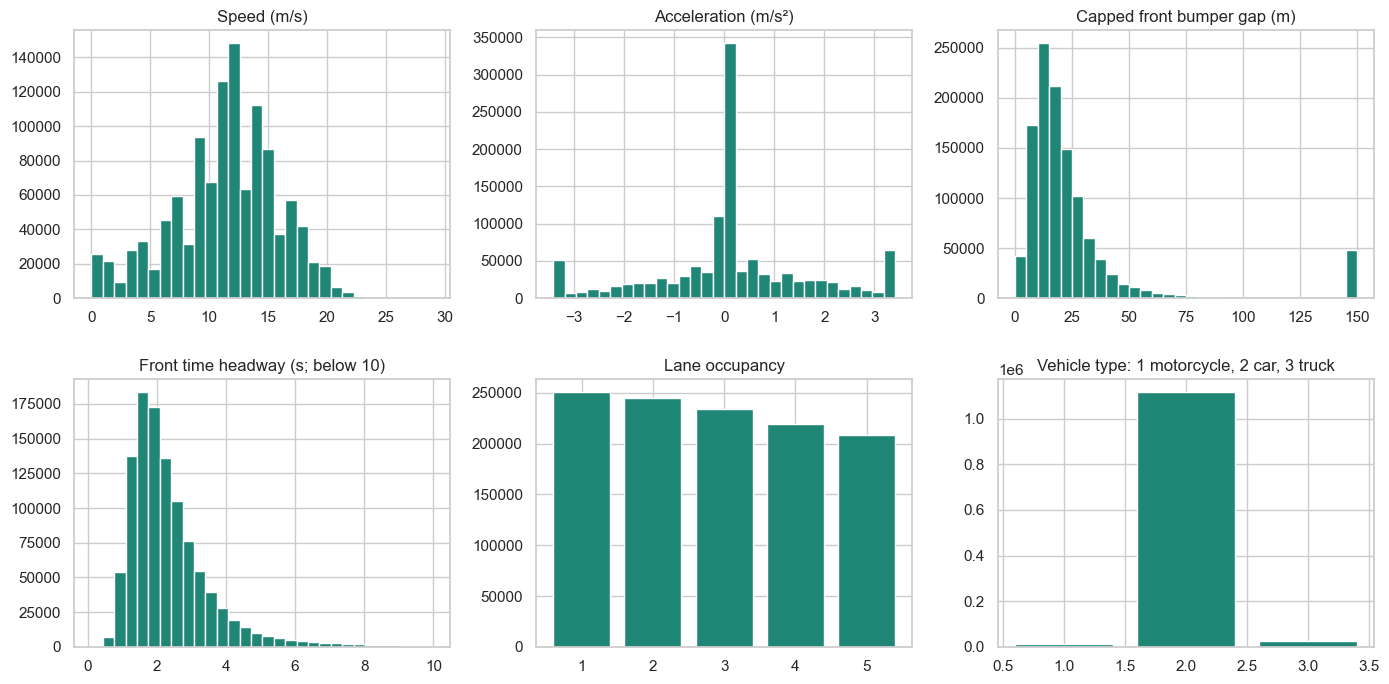

In [5]:
fig,axes=plt.subplots(2,3,figsize=(14,7))
for ax,c,title in zip(axes.flat,['v_vel','v_acc','front_gap','headway','lane_id','v_class'],['Speed (m/s)','Acceleration (m/s²)','Capped front bumper gap (m)','Front time headway (s; below 10)','Lane occupancy','Vehicle type: 1 motorcycle, 2 car, 3 truck']):
    values=observed.loc[valid_leader,c].replace([np.inf,-np.inf],np.nan).dropna()
    if c=='headway': values=values[values<10]
    if c in ['lane_id','v_class']:
        counts=values.value_counts().sort_index(); ax.bar(counts.index,counts.values,color='#208777')
    else: ax.hist(values,bins=30,color='#208777')
    ax.set_title(title)
plt.tight_layout(); plt.show()

## 4. Labels from actual future lane IDs
At every current observation, require all 20 subsequent frames at exactly 100 ms intervals, in mainline lanes, with no jump larger than one lane between successive frames. Label **1** if an adjacent crossing occurs anywhere in this complete window; otherwise label **0**. A return to the original lane still counts as a change. Missing/truncated windows are excluded even if an early change was seen. No accident, headway or gap threshold determines the label. The following code labels all 10 Hz observations before thinning to 1 Hz.

In [6]:
future_group=df.groupby('vehicle_id',sort=False)
complete=pd.Series(True,index=df.index)
changed=pd.Series(False,index=df.index)
previous_lane=df.lane_id
for step in range(1,21):
    future=future_group[['global_time','lane_id']].shift(-step)
    difference=(future.lane_id-previous_lane).abs()
    complete &= future.global_time.eq(df.global_time+100*step)&future.lane_id.between(1,5)&difference.le(1)
    changed |= difference.eq(1)
    previous_lane=future.lane_id
df['target']=changed.astype(int)
eligible=observed[complete.to_numpy()&valid_leader.to_numpy()&observed[features].notna().all(axis=1).to_numpy()].copy()
eligible['target']=df.loc[eligible.index,'target']
previous=df.groupby('vehicle_id')[['global_time','lane_id']].shift()
transition_mask=df.global_time.sub(previous.global_time).eq(100)&df.lane_id.sub(previous.lane_id).abs().eq(1)
transition_count=int(transition_mask.sum())
print('Observed crossings:',transition_count,'Eligible 10 Hz windows:',len(eligible))
print('Future-window classes:',eligible.target.value_counts().to_dict())
assert set(eligible.target.unique())=={0,1}

Observed crossings: 812 Eligible 10 Hz windows: 1103092
Future-window classes: {0: 1090094, 1: 12998}


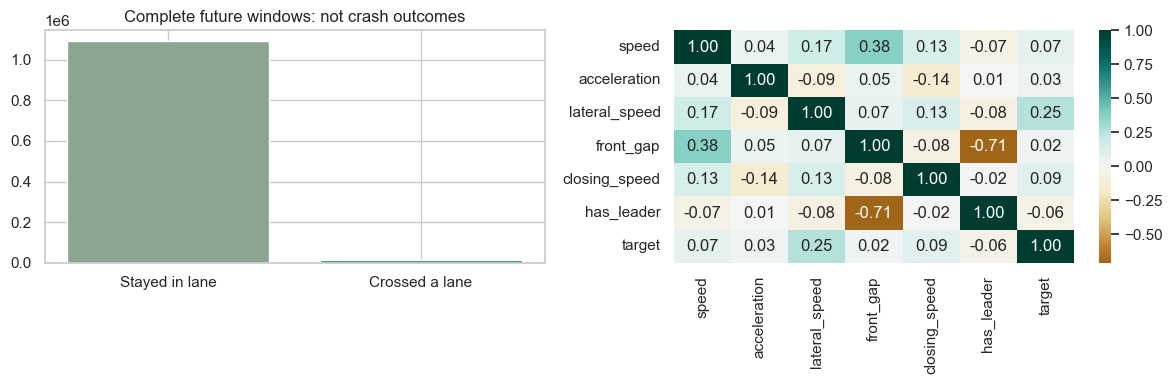

Positive windows can overlap around one actual crossing; window counts are not unique maneuver counts.


In [7]:
fig,axes=plt.subplots(1,2,figsize=(12,4))
counts=eligible.target.value_counts().reindex([0,1],fill_value=0)
axes[0].bar(['Stayed in lane','Crossed a lane'],counts.values,color=['#8ca590','#208777']); axes[0].set_title('Complete future windows: not crash outcomes')
sample=eligible.sample(min(5000,len(eligible)),random_state=42)
sns.heatmap(sample[features+['target']].corr(),annot=True,fmt='.2f',cmap='BrBG',center=0,ax=axes[1]); plt.tight_layout(); plt.show()
print('Positive windows can overlap around one actual crossing; window counts are not unique maneuver counts.')

## 5. Isolated chronological partitions
Use chronological 60/20/20 blocks. Exclude vehicles whose complete raw trajectory crosses a boundary, for both the ego and any current leader. No vehicle ID is shared across partitions. Require the full two-second outcome inside the partition. Thin current samples to 1 Hz only after label construction. The test set is not used for tuning or selection.

In [8]:
start,end=raw.global_time.min(),raw.global_time.max()
cut1,cut2=start+.6*(end-start),start+.8*(end-start)
bounds=raw.groupby('vehicle_id').global_time.agg(['min','max'])
parts=[]
for low,high in [(start,cut1),(cut1,cut2),(cut2,end+1)]:
    ids=bounds.index[(bounds['min']>=low)&(bounds['max']<high)]
    part=eligible[eligible.vehicle_id.isin(ids)&(eligible.preceding.eq(0)|eligible.preceding.isin(ids))&(eligible.global_time>=low)&(eligible.global_time+2000<high)&(eligible.frame_id%10==0)].copy()
    parts.append(part)
train,validation,test=parts
for name,p in zip(['train','validation','test'],parts): print(name,len(p),p.target.value_counts().to_dict())
for a,b in [(train,validation),(train,test),(validation,test)]:
    assert not (set(a.vehicle_id)|set(a.preceding)-{0})&(set(b.vehicle_id)|set(b.preceding)-{0})
assert all(p.target.nunique()==2 for p in parts)
X,y=train[features],train.target

train 58757 {0: 57936, 1: 821}
validation 14897 {0: 14692, 1: 205}
test 17625 {0: 17488, 1: 137}


## 6. Training-only preprocessing and tuning
All three classifiers receive identical features and partitions. Expanding training folds purge vehicles shared across fold sides, including current leaders, and embargo future windows. Scaling is fitted within each fold. Compare ordinary and balanced priors/weights because lane changes are rare. Validation F1 selects the model, with average precision then ROC-AUC breaking ties. Accuracy alone can be misleading when almost everyone stays in lane.

In [9]:
folds=[]
for fraction in [.5,.7,.85]:
    boundary=train.global_time.quantile(fraction)
    a=train[train.global_time+2000<boundary]
    b=train[(train.global_time>boundary)&(train.global_time<boundary+.14*(cut1-start))]
    shared=((set(a.vehicle_id)|set(a.preceding))&(set(b.vehicle_id)|set(b.preceding)))-{0}
    a=a[~a.vehicle_id.isin(shared)&~a.preceding.isin(shared)]
    b=b[~b.vehicle_id.isin(shared)&~b.preceding.isin(shared)]
    if a.target.nunique()==2 and b.target.nunique()==2: folds.append((np.flatnonzero(train.index.isin(a.index)),np.flatnonzero(train.index.isin(b.index))))
assert len(folds)>=2
print('Purged CV sizes:',[(len(a),len(b)) for a,b in folds])
def evaluate(model,part,threshold=.5):
    prob=model.predict_proba(part[features])[:,1]; pred=(prob>=threshold).astype(int)
    return dict(accuracy=accuracy_score(part.target,pred),precision=precision_score(part.target,pred,zero_division=0),recall=recall_score(part.target,pred,zero_division=0),f1=f1_score(part.target,pred,zero_division=0),roc_auc=roc_auc_score(part.target,prob),average_precision=average_precision_score(part.target,prob),balanced_accuracy=balanced_accuracy_score(part.target,pred),confusion_matrix=confusion_matrix(part.target,pred).tolist())
models={}; results=[]
print('After training-only grid search, each candidate threshold is selected on validation from a fixed grid; test is untouched.')

Purged CV sizes: [(26209, 5786), (38203, 6102), (46999, 5549)]
After training-only grid search, each candidate threshold is selected on validation from a fixed grid; test is untouched.


In [10]:
search=GridSearchCV(Pipeline([('scale',StandardScaler()),('model',LogisticRegression(max_iter=2000,random_state=42))]),{'model__C':[.1,1,10],'model__class_weight':[None,'balanced']},cv=folds,scoring='f1',n_jobs=1,error_score='raise')
search.fit(X,y)
models['Logistic Regression']=search.best_estimator_
threshold=max([.05,.1,.15,.2,.3,.4,.5,.6,.7,.8,.9],key=lambda t:(evaluate(search.best_estimator_,validation,t)['f1'],evaluate(search.best_estimator_,validation,t)['precision'],t))
results.append(dict(name='Logistic Regression',cv_f1=search.best_score_,parameters=search.best_params_,threshold=threshold,training=evaluate(search.best_estimator_,train,threshold),validation=evaluate(search.best_estimator_,validation,threshold)))
print(results[-1])

{'name': 'Logistic Regression', 'cv_f1': np.float64(0.1256854256854257), 'parameters': {'model__C': 1, 'model__class_weight': None}, 'threshold': 0.1, 'training': {'accuracy': 0.9781302653300883, 'precision': 0.27120315581854043, 'recall': 0.33495736906211937, 'f1': 0.2997275204359673, 'roc_auc': 0.8293303232497131, 'average_precision': 0.20503322284303618, 'balanced_accuracy': 0.6611009573838628, 'confusion_matrix': [[57197, 739], [546, 275]]}, 'validation': {'accuracy': 0.9821440558501712, 'precision': 0.3435897435897436, 'recall': 0.32682926829268294, 'f1': 0.335, 'roc_auc': 0.8017766430046549, 'average_precision': 0.2243387455632761, 'balanced_accuracy': 0.6590585219764531, 'confusion_matrix': [[14564, 128], [138, 67]]}}


In [11]:
search=GridSearchCV(Pipeline([('scale',StandardScaler()),('model',LinearDiscriminantAnalysis(solver='lsqr'))]),{'model__shrinkage':['auto',.1],'model__priors':[None,[.5,.5]]},cv=folds,scoring='f1',n_jobs=1,error_score='raise')
search.fit(X,y)
models['LDA']=search.best_estimator_
threshold=max([.05,.1,.15,.2,.3,.4,.5,.6,.7,.8,.9],key=lambda t:(evaluate(search.best_estimator_,validation,t)['f1'],evaluate(search.best_estimator_,validation,t)['precision'],t))
results.append(dict(name='LDA',cv_f1=search.best_score_,parameters=search.best_params_,threshold=threshold,training=evaluate(search.best_estimator_,train,threshold),validation=evaluate(search.best_estimator_,validation,threshold)))
print(results[-1])

{'name': 'LDA', 'cv_f1': np.float64(0.19837645865043121), 'parameters': {'model__priors': None, 'model__shrinkage': 0.1}, 'threshold': 0.6, 'training': {'accuracy': 0.9777728611059108, 'precision': 0.26108374384236455, 'recall': 0.3227771010962241, 'f1': 0.2886710239651416, 'roc_auc': 0.8136204139407388, 'average_precision': 0.1807765527121136, 'balanced_accuracy': 0.6549158910617823, 'confusion_matrix': [[57186, 750], [556, 265]]}, 'validation': {'accuracy': 0.9798617171242532, 'precision': 0.30612244897959184, 'recall': 0.36585365853658536, 'f1': 0.3333333333333333, 'roc_auc': 0.8030711918880691, 'average_precision': 0.20476083940310028, 'balanced_accuracy': 0.6771413677926597, 'confusion_matrix': [[14522, 170], [130, 75]]}}


In [12]:
search=GridSearchCV(Pipeline([('scale',StandardScaler()),('model',QuadraticDiscriminantAnalysis())]),{'model__reg_param':[.05,.2,.5],'model__priors':[None,[.5,.5]]},cv=folds,scoring='f1',n_jobs=1,error_score='raise')
search.fit(X,y)
models['QDA']=search.best_estimator_
threshold=max([.05,.1,.15,.2,.3,.4,.5,.6,.7,.8,.9],key=lambda t:(evaluate(search.best_estimator_,validation,t)['f1'],evaluate(search.best_estimator_,validation,t)['precision'],t))
results.append(dict(name='QDA',cv_f1=search.best_score_,parameters=search.best_params_,threshold=threshold,training=evaluate(search.best_estimator_,train,threshold),validation=evaluate(search.best_estimator_,validation,threshold)))
print(results[-1])

{'name': 'QDA', 'cv_f1': np.float64(0.191123418839658), 'parameters': {'model__priors': None, 'model__reg_param': 0.2}, 'threshold': 0.4, 'training': {'accuracy': 0.96352774988512, 'precision': 0.1606776180698152, 'recall': 0.3812423873325213, 'f1': 0.2260743950884796, 'roc_auc': 0.8446711727098758, 'average_precision': 0.10461763946292058, 'balanced_accuracy': 0.6765107959860618, 'confusion_matrix': [[56301, 1635], [508, 313]]}, 'validation': {'accuracy': 0.9675102369604618, 'precision': 0.1934065934065934, 'recall': 0.4292682926829268, 'f1': 0.26666666666666666, 'roc_auc': 0.824347247216006, 'average_precision': 0.11486491409310101, 'balanced_accuracy': 0.7021443559793615, 'confusion_matrix': [[14325, 367], [117, 88]]}}


,model,cv_f1,train_f1,accuracy,precision,recall,f1,roc_auc,average_precision,balanced_accuracy
0,Logistic Regression,0.125685,0.299728,0.982144,0.343590,0.326829,0.335000,0.801777,0.224339,0.659059
1,LDA,0.198376,0.288671,0.979862,0.306122,0.365854,0.333333,0.803071,0.204761,0.677141
2,QDA,0.191123,0.226074,0.967510,0.193407,0.429268,0.266667,0.824347,0.114865,0.702144


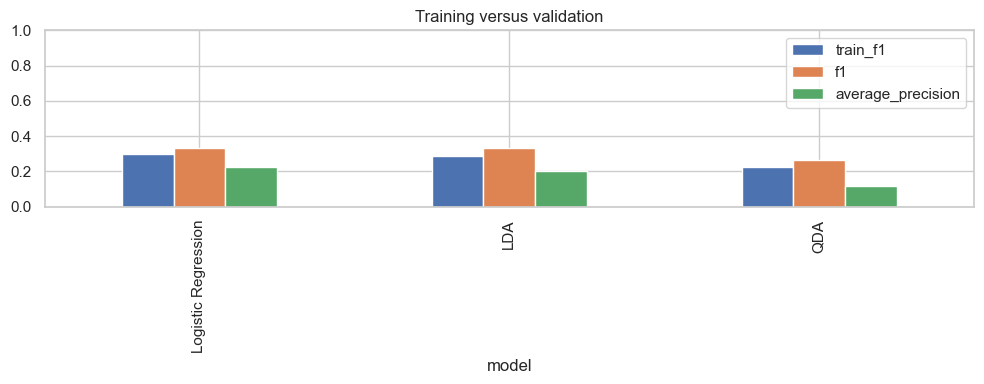

Large gaps suggest overfitting or distribution shift. Close scores do not establish external generalization.


In [13]:
comparison=pd.DataFrame([dict(model=r['name'],cv_f1=r['cv_f1'],train_f1=r['training']['f1'],**{k:v for k,v in r['validation'].items() if k!='confusion_matrix'}) for r in results])
display(comparison)
comparison.set_index('model')[['train_f1','f1','average_precision']].plot.bar(ylim=(0,1),figsize=(10,4)); plt.title('Training versus validation'); plt.tight_layout(); plt.show()
print('Large gaps suggest overfitting or distribution shift. Close scores do not establish external generalization.')

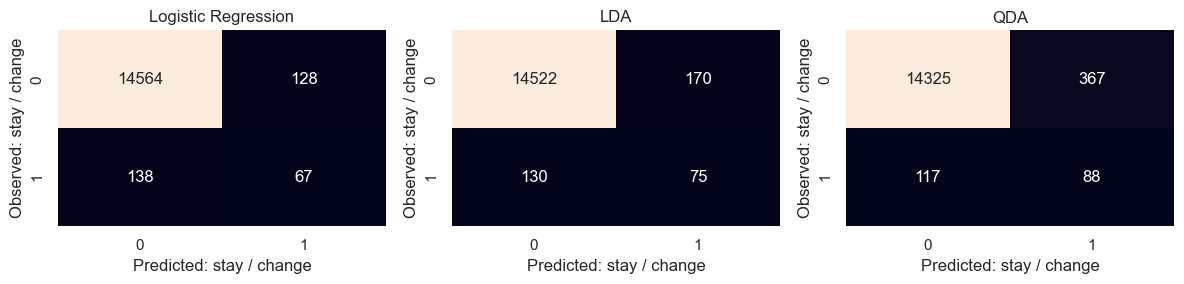

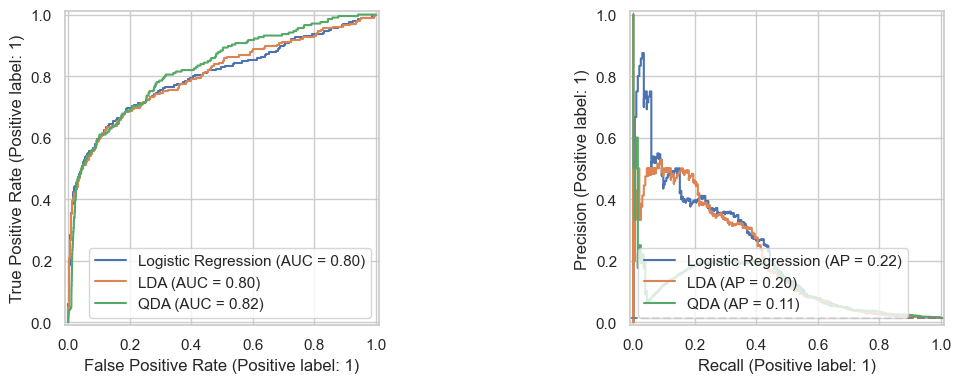

In [14]:
fig,axes=plt.subplots(1,3,figsize=(12,3))
for ax,r in zip(axes,results):
    sns.heatmap(r['validation']['confusion_matrix'],annot=True,fmt='d',cbar=False,ax=ax); ax.set(title=r['name'],xlabel='Predicted: stay / change',ylabel='Observed: stay / change')
plt.tight_layout(); plt.show()
fig,axes=plt.subplots(1,2,figsize=(12,4))
for name,model in models.items():
    RocCurveDisplay.from_estimator(model,validation[features],validation.target,ax=axes[0],name=name)
    PrecisionRecallDisplay.from_estimator(model,validation[features],validation.target,ax=axes[1],name=name)
axes[1].axhline(validation.target.mean(),linestyle='--',color='gray',label='Positive prevalence'); plt.tight_layout(); plt.show()

## 7. Select, then evaluate once on untouched test data
Select by validation F1, then average precision and ROC-AUC. Retain the training-fitted pipeline without refitting on validation, so the export is exactly the tested model. Compare with the simple rule that every car stays in its lane. Its accuracy can be very high while its lane-change recall and F1 are zero. Report uncalibrated scores as estimated behavior probabilities, never accident probabilities or safety recommendations.

In [15]:
winner=max(results,key=lambda r:(r['validation']['f1'],r['validation']['average_precision'],r['validation']['roc_auc']))
selected=models[winner['name']]
test_metrics=evaluate(selected,test,winner['threshold'])
baseline=dict(name='Always stay in lane',accuracy=float((test.target==0).mean()),precision=0.,recall=0.,f1=0.,balanced_accuracy=.5,roc_auc=.5,average_precision=float(test.target.mean()))
print('Selected:',winner['name']); print('Untouched test:',test_metrics); print('Baseline:',baseline)
test_probability=selected.predict_proba(test[features])[:,1]
test_prediction=(test_probability>=winner['threshold']).astype(int)

Selected: Logistic Regression
Untouched test: {'accuracy': 0.9878581560283688, 'precision': 0.22695035460992907, 'recall': 0.23357664233576642, 'f1': 0.2302158273381295, 'roc_auc': 0.8873312920309067, 'average_precision': 0.1645228354555062, 'balanced_accuracy': 0.6136718984780387, 'confusion_matrix': [[17379, 109], [105, 32]]}
Baseline: {'name': 'Always stay in lane', 'accuracy': 0.99222695035461, 'precision': 0.0, 'recall': 0.0, 'f1': 0.0, 'balanced_accuracy': 0.5, 'roc_auc': 0.5, 'average_precision': 0.007773049645390071}


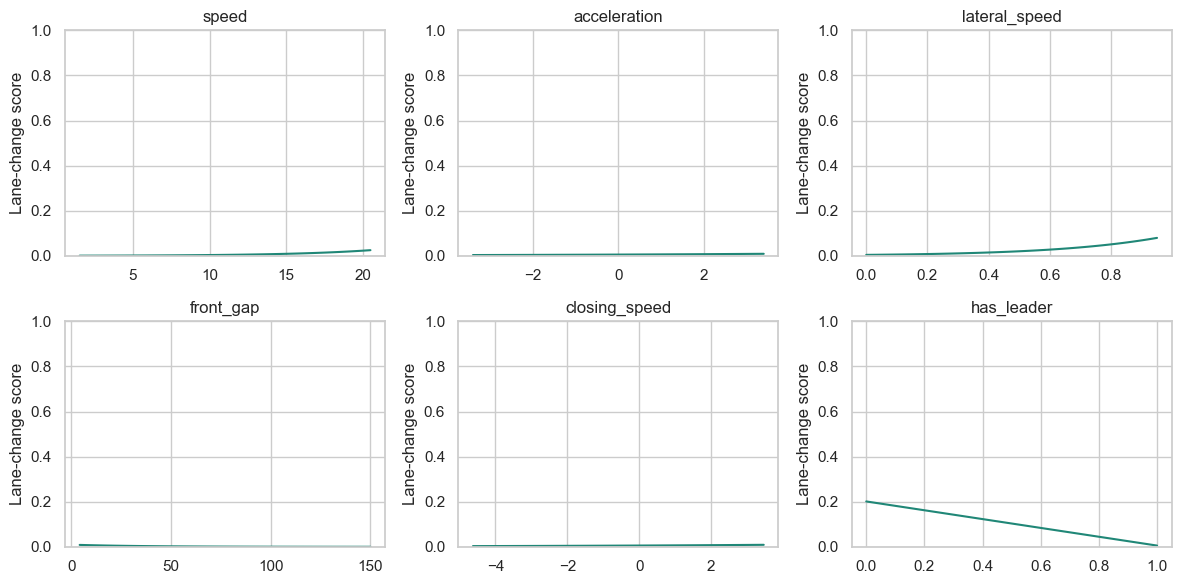

Response curves describe fitted associations, not causal effects or hidden driver intention.


In [16]:
fig,axes=plt.subplots(2,3,figsize=(12,6))
for ax,feature in zip(axes.flat,features):
    grid=pd.DataFrame([X.median()]*60)
    grid[feature]=np.linspace(X[feature].quantile(.01),X[feature].quantile(.99),60)
    if feature=='has_leader': grid[feature]=(grid[feature]>.5).astype(int)
    ax.plot(grid[feature],selected.predict_proba(grid)[:,1],color='#208777'); ax.set(title=feature,ylabel='Lane-change score',ylim=(0,1))
plt.tight_layout(); plt.show()
print('Response curves describe fitted associations, not causal effects or hidden driver intention.')

## 8. Export the exact model, schema and metrics
Portable parameters reproduce the selected fitted scaler and classifier in the browser. QDA exports its fitted class means, rotations, variances and priors; linear models export their fitted coefficients. This is local inference using the same learned model, not a hand-designed percentage. Export held-out probability checks to verify numerical equivalence. Runtime inputs outside training support receive no score.

In [17]:
scale=selected.named_steps['scale']; classifier=selected.named_steps['model']
portable=dict(mean=scale.mean_.tolist(),scale=scale.scale_.tolist())
if winner['name']=='QDA':
    portable.update(kind='scaled-qda',means=classifier.means_.tolist(),rotations=[r.tolist() for r in classifier.rotations_],variances=[s.tolist() for s in classifier.scalings_],priors=classifier.priors_.tolist())
else: portable.update(kind='scaled-logit',coefficients=classifier.coef_[0].tolist(),intercept=float(classifier.intercept_[0]))
info=dict(task='lane-change-behavior',version='behavior-1',name=winner['name'],features=features,units=dict(speed='m/s',acceleration='m/s²',lateral_speed='m/s; previous 0.5 s absolute mean',front_gap='m; capped at 150',closing_speed='m/s; ego minus leader',has_leader='0 or 1'),ranges={c:[float(X[c].min()),float(X[c].max())] for c in features},horizon_seconds=2,history_seconds=.5,labels={'0':'Stay in lane','1':'Lane change'},target='Any recorded adjacent mainline lane-ID crossing within the next complete 20 observations at 100 ms intervals',decision_threshold=float(winner['threshold']),browser_model=portable,limitations=['Observed lane-ID crossing, not accident or feasibility prediction','Lateral motion can already be underway','One recording; evaluate independent recordings for external generalization','Probabilities are uncalibrated','Leader absence uses an explicit flag and capped gap encoding'])
supported=test[test[features].ge(X.min()).all(axis=1)&test[features].le(X.max()).all(axis=1)]
info['checks']=[dict(inputs=row[features].to_dict(),probability=float(selected.predict_proba(pd.DataFrame([row[features]]))[0,1])) for _,row in supported.head(12).iterrows()]
metrics=dict(task=info['task'],version=info['version'],selected_model=winner['name'],comparison=results,test=test_metrics,baseline=baseline,split_sizes={n:len(p) for n,p in zip(['train','validation','test'],parts)},class_counts={n:{str(k):int(v) for k,v in p.target.value_counts().items()} for n,p in zip(['train','validation','test'],parts)},protocol='Chronological 60/20/20; disjoint ego and current leader trajectories; full two-second outcome embargo; purged training CV; validation selection; once-only test')
joblib.dump(selected,OUT/'behavior.joblib')
for name,value in [('info',info),('metrics',metrics)]:
    for folder in [OUT,PUBLIC]: (folder/f'{name}.json').write_text(json.dumps(value,indent=2,allow_nan=False),encoding='utf-8')
(OUT/'example.json').write_text(json.dumps(info['checks'][0]['inputs'],indent=2))
assert np.allclose(joblib.load(OUT/'behavior.joblib').predict_proba(test[features])[:,1],test_probability)
print('Exported fitted behavior model:',winner['name'])

Exported fitted behavior model: Logistic Regression


## 9. Replay held-out recorded outcomes
Examples cover correct and incorrect stay/change predictions where available, with different ego vehicles. A score is computed from the assessment-time inputs only and frozen while actual future positions replay. The actual outcome is revealed at the end. The sample is illustrative, not a representative estimate of accuracy; use full test metrics for performance. Traces and nearby vehicles are recorded samples, not model-controlled animations.

In [18]:
lookup=df.set_index(['vehicle_id','global_time'])
frames={int(t):f for t,f in df.groupby('global_time')}
candidate=test.copy(); candidate['probability']=test_probability; candidate['predicted']=test_prediction
examples=[]; used=set()
for actual,predicted in [(1,1),(1,0),(0,1),(0,0)]:
    for _,row in candidate[(candidate.target==actual)&(candidate.predicted==predicted)].iterrows():
        if int(row.vehicle_id) in used: continue
        current=int(row.global_time); vehicle_id=int(row.vehicle_id)
        scene=frames[current]
        ids=scene.assign(distance=(scene.local_y-row.local_y).abs()).sort_values('distance').head(10).vehicle_id.astype(int).tolist()
        snapshots=[]
        for step in range(21):
            instant=current+step*100; f=frames[instant]; f=f[f.vehicle_id.isin(ids)]
            snapshots.append(dict(seconds=step/10,cars=[dict(id=int(v.vehicle_id),x=float(v.local_y-row.local_y+30),y=float(v.local_x),lane=int(v.lane_id),speed=float(v.v_vel),length=float(v.v_length),width=float(v.v_width)) for v in f.itertuples()]))
        examples.append(dict(id=len(examples)+1,vehicle_id=vehicle_id,timestamp=current,initial_lane=int(row.lane_id),actual=int(actual),predicted=int(predicted),probability=float(row.probability),inputs=row[features].to_dict(),supported=bool(row[features].ge(X.min()).all() and row[features].le(X.max()).all()),snapshots=snapshots))
        used.add(vehicle_id)
        if sum(e['actual']==actual and e['predicted']==predicted for e in examples)>=4: break
replay=dict(task=info['task'],version=info['version'],horizon_seconds=2,source='Held-out NGSIM observations; ten nearby vehicles per scene',examples=examples)
for folder in [OUT,PUBLIC]: (folder/'replay.json').write_text(json.dumps(replay,indent=2,allow_nan=False),encoding='utf-8')
print('Held-out replay examples:',len(examples))

Held-out replay examples: 16


## 10. Traffic distributions and data-informed simulation initialization
EDA uses real observations. For generated scenes, export coherent **training-period snapshots** containing real combinations of speeds, accelerations, lengths and lanes. A configurable simulator can remap lane indices and separate overlaps after remapping; those scenes are adaptations, not historical replays or guaranteed exact reproductions of the original distributions. Distinguish these from the held-out replay and from deliberately constructed collision demonstrations.

In [19]:
def histogram(values,bins=20):
    values=values.replace([np.inf,-np.inf],np.nan).dropna()
    if values.name in ['lane_id','v_class','target']:
        return [dict(value=int(v),count=int(n)) for v,n in values.value_counts().sort_index().items()]
    counts,edges=np.histogram(values,bins=bins)
    return [dict(value=float((a+b)/2),count=int(n)) for a,b,n in zip(edges[:-1],edges[1:],counts)]
traffic_seeds=[]
for instant in np.linspace(train.global_time.min(),train.global_time.max(),12):
    t=min(frames,key=lambda x:abs(x-instant)); f=frames[t].sort_values('local_y')
    if len(f)<30: continue
    f=f.head(40); origin=f.local_y.min()
    traffic_seeds.append([dict(source_id=int(v.vehicle_id),lane=int(v.lane_id)-1,x=float(v.local_y-origin+20),speed=float(v.v_vel),accel=float(v.v_acc),length=float(v.v_length),width=float(v.v_width),type={1:'Motorcycle',2:'Car',3:'Truck'}[int(v.v_class)]) for v in f.itertuples()])
analytics=dict(task=info['task'],version=info['version'],rows=len(raw),vehicles=int(raw.vehicle_id.nunique()),recording_count=1,duration_seconds=float((end-start)/1000),eligible_rows=len(eligible),recorded_crossings=transition_count,positive_rate=float(eligible.target.mean()),class_counts={str(k):int(v) for k,v in eligible.target.value_counts().items()},source=SOURCE,sha256=hashlib.sha256(path.read_bytes()).hexdigest(),missing_values=raw.isna().sum().to_dict(),duplicates=duplicates,histograms={c:histogram(observed.loc[valid_leader,c].clip(upper=10) if c=='headway' else observed.loc[valid_leader,c]) for c in ['v_vel','v_acc','front_gap','headway','lane_id','v_class']},correlation=sample[features+['target']].corr().fillna(0).round(3).to_dict(),statistics=df[['v_vel','v_acc','v_length','space_headway']].agg(['mean','median','var','std','min','max']).to_dict(),traffic_seeds=traffic_seeds)
for folder in [OUT,PUBLIC]: (folder/'analytics.json').write_text(json.dumps(analytics,indent=2,allow_nan=False),encoding='utf-8')
print('Training-period traffic snapshots:',len(traffic_seeds))

Training-period traffic snapshots: 11


## Conclusion
The project predicts a recorded vehicle's lane crossing within a complete two-second future window. It compares Logistic Regression, LDA and QDA using common current/past features, isolated chronological partitions and training-only tuning. Test performance must be compared with always staying in lane, including minority-class recall, F1 and average precision.

The model estimates observed behavior, not verified accidents, safe maneuvers or the best lane to choose. Recorded replay follows actual observations independently of predictions. Generated scenes use adapted training snapshots or explicitly synthetic presets; their movement controller and geometric collision detection remain separate. A single recording, class imbalance, noisy lane IDs and cues from lateral motion already underway limit generalization. Independent-recording validation is needed before broader claims.